In [1]:
import os

print("Lokasi Notebook saat ini:")
print(os.getcwd())

print("\nIsi folder saat ini:")
print(os.listdir())

Lokasi Notebook saat ini:
C:\Users\Neysalva Calista\Downloads\Global_Climate_Change_UTS\Global_Climate_Change_UTS\scripts

Isi folder saat ini:
['.ipynb_checkpoints', 'clean_data.py', 'Untitled.ipynb', 'Untitled1.ipynb']


In [2]:
import os

print(os.listdir("dataset"))

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'dataset'

In [3]:
import os

os.chdir(r"C:\Users\Neysalva Calista\Downloads\Global_Climate_Change_UTS\Global_Climate_Change_UTS")

print("Lokasi kerja sekarang:")
print(os.getcwd())

print("\nIsi folder proyek:")
print(os.listdir())

Lokasi kerja sekarang:
C:\Users\Neysalva Calista\Downloads\Global_Climate_Change_UTS\Global_Climate_Change_UTS

Isi folder proyek:
['.ipynb_checkpoints', 'app.py', 'dataset', 'README.md', 'requirements.txt', 'scripts']


In [4]:
print(os.listdir("dataset"))

['climate_change_clean.csv', 'Environment_Temperature_change_E_All_Data_NOFLAG.csv']


In [5]:
import pandas as pd

df = pd.read_csv(
    "dataset/Environment_Temperature_change_E_All_Data_NOFLAG.csv",
    encoding="latin1"
)

df.head()

,Area Code,Area,Months Code,Months,Element Code,Element,Unit,Y1961,Y1962,Y1963,...,Y2010,Y2011,Y2012,Y2013,Y2014,Y2015,Y2016,Y2017,Y2018,Y2019
0,2,Afghanistan,7001,January,7271,Temperature change,°C,0.777,0.062,2.744,...,3.601,1.179,-0.583,1.233,1.755,1.943,3.416,1.201,1.996,2.951
1,2,Afghanistan,7001,January,6078,Standard Deviation,°C,1.950,1.950,1.950,...,1.950,1.950,1.950,1.950,1.950,1.950,1.950,1.950,1.950,1.950
2,2,Afghanistan,7002,February,7271,Temperature change,°C,-1.743,2.465,3.919,...,1.212,0.321,-3.201,1.494,-3.187,2.699,2.251,-0.323,2.705,0.086
3,2,Afghanistan,7002,February,6078,Standard Deviation,°C,2.597,2.597,2.597,...,2.597,2.597,2.597,2.597,2.597,2.597,2.597,2.597,2.597,2.597
4,2,Afghanistan,7003,March,7271,Temperature change,°C,0.516,1.336,0.403,...,3.390,0.748,-0.527,2.246,-0.076,-0.497,2.296,0.834,4.418,0.234


In [6]:
# Melihat jumlah baris dan kolom
print("Ukuran Dataset:", df.shape)

# Melihat informasi dataset
df.info()

Ukuran Dataset: (9656, 66)
<class 'pandas.DataFrame'>
RangeIndex: 9656 entries, 0 to 9655
Data columns (total 66 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Area Code     9656 non-null   int64  
 1   Area          9656 non-null   str    
 2   Months Code   9656 non-null   int64  
 3   Months        9656 non-null   str    
 4   Element Code  9656 non-null   int64  
 5   Element       9656 non-null   str    
 6   Unit          9656 non-null   str    
 7   Y1961         8287 non-null   float64
 8   Y1962         8322 non-null   float64
 9   Y1963         8294 non-null   float64
 10  Y1964         8252 non-null   float64
 11  Y1965         8281 non-null   float64
 12  Y1966         8364 non-null   float64
 13  Y1967         8347 non-null   float64
 14  Y1968         8345 non-null   float64
 15  Y1969         8326 non-null   float64
 16  Y1970         8308 non-null   float64
 17  Y1971         8303 non-null   float64
 18  Y1972       

In [7]:
# Menghitung jumlah data kosong
print("Total Data Kosong:", df.isnull().sum().sum())

# Melihat jumlah data kosong setiap kolom
df.isnull().sum()

Total Data Kosong: 78103


Area Code          0
Area               0
Months Code        0
Months             0
Element Code       0
                ... 
Y2015           1295
Y2016           1308
Y2017           1290
Y2018           1307
Y2019           1291
Length: 66, dtype: int64

In [8]:
# Melihat kategori pengukuran
df["Element"].value_counts()

Element
Temperature change    4828
Standard Deviation    4828
Name: count, dtype: int64

In [9]:
# Mengambil data Temperature change saja
df_clean = df[df["Element"] == "Temperature change"].copy()

# Mengambil seluruh kolom tahun
year_cols = [col for col in df_clean.columns if col.startswith("Y")]

# Mengubah struktur data dari wide ke long
df_long = df_clean.melt(
    id_vars=["Area", "Months", "Unit"],
    value_vars=year_cols,
    var_name="Year",
    value_name="Temperature_Change"
)

# Mengubah format tahun menjadi angka
df_long["Year"] = (
    df_long["Year"]
    .str.replace("Y", "", regex=False)
    .astype(int)
)

# Memastikan nilai temperatur berupa angka
df_long["Temperature_Change"] = pd.to_numeric(
    df_long["Temperature_Change"],
    errors="coerce"
)

# Menghapus data temperatur kosong
df_long = df_long.dropna(subset=["Temperature_Change"])

# Mengurutkan data
df_long = df_long.sort_values(
    by=["Area", "Year"]
).reset_index(drop=True)

# Menampilkan hasil
df_long.head()

,Area,Months,Unit,Year,Temperature_Change
0,Afghanistan,January,°C,1961,0.777
1,Afghanistan,February,°C,1961,-1.743
2,Afghanistan,March,°C,1961,0.516
3,Afghanistan,April,°C,1961,-1.709
4,Afghanistan,May,°C,1961,1.412


In [10]:
print("Jumlah Baris dan Kolom:", df_long.shape)

print("\nJumlah Negara/Wilayah:", df_long["Area"].nunique())

print("\nRentang Tahun:")
print(df_long["Year"].min(), "-", df_long["Year"].max())

print("\nJumlah Data Kosong:")
print(df_long.isnull().sum().sum())

print("\nInformasi Dataset:")
df_long.info()

Jumlah Baris dan Kolom: (254761, 5)

Jumlah Negara/Wilayah: 284

Rentang Tahun:
1961 - 2019

Jumlah Data Kosong:
0

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 254761 entries, 0 to 254760
Data columns (total 5 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Area                254761 non-null  str    
 1   Months              254761 non-null  str    
 2   Unit                254761 non-null  str    
 3   Year                254761 non-null  int64  
 4   Temperature_Change  254761 non-null  float64
dtypes: float64(1), int64(1), str(3)
memory usage: 15.5 MB


In [11]:
df_long.to_csv(
    "dataset/climate_change_clean.csv",
    index=False
)

print("Dataset bersih berhasil disimpan!")

Dataset bersih berhasil disimpan!


In [12]:
# Statistik deskriptif perubahan temperatur
df_long["Temperature_Change"].describe()

count    254761.000000
mean          0.485495
std           1.003162
min          -9.334000
25%          -0.064000
50%           0.416000
75%           0.982000
max          11.759000
Name: Temperature_Change, dtype: float64

In [13]:
# Rata-rata perubahan temperatur berdasarkan tahun
annual_avg = (
    df_long.groupby("Year")["Temperature_Change"]
    .mean()
    .reset_index()
)

annual_avg.head()

,Year,Temperature_Change
0,1961,0.144488
1,1962,-0.028981
2,1963,-0.026252
3,1964,-0.122131
4,1965,-0.224178


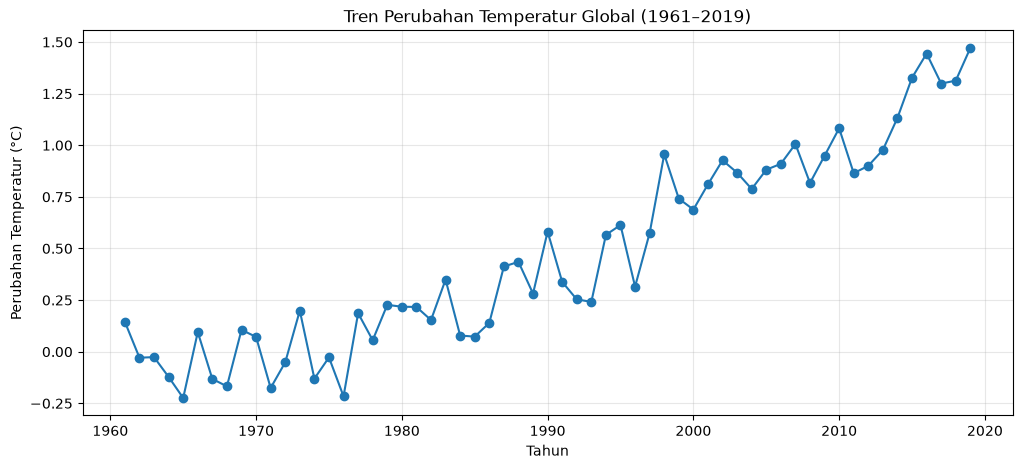

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    annual_avg["Year"],
    annual_avg["Temperature_Change"],
    marker="o"
)

plt.title("Tren Perubahan Temperatur Global (1961–2019)")
plt.xlabel("Tahun")
plt.ylabel("Perubahan Temperatur (°C)")
plt.grid(True, alpha=0.3)

plt.show()

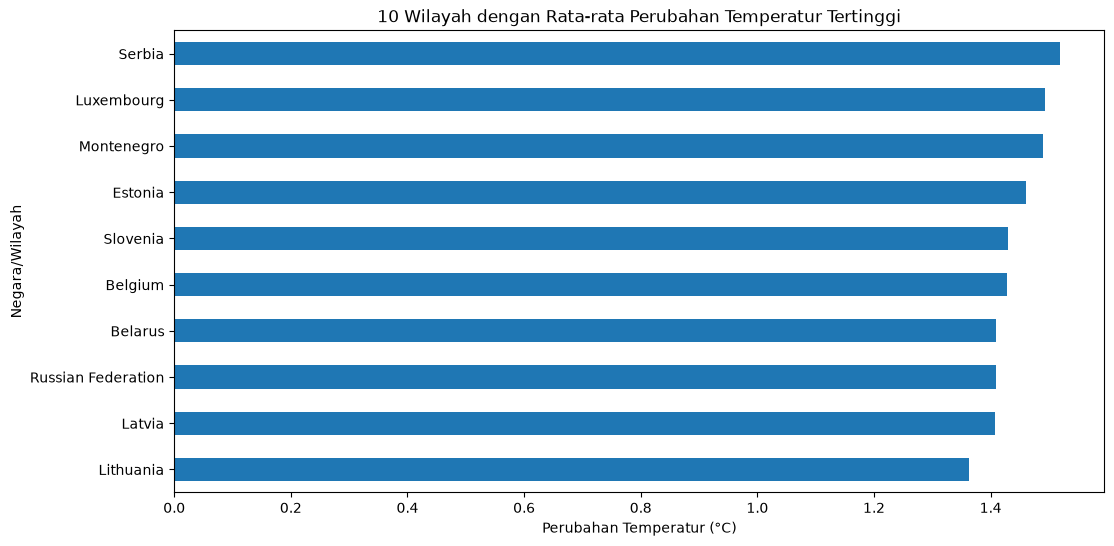

In [15]:
area_avg = (
    df_long.groupby("Area")["Temperature_Change"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

area_avg.sort_values().plot(kind="barh")

plt.title("10 Wilayah dengan Rata-rata Perubahan Temperatur Tertinggi")
plt.xlabel("Perubahan Temperatur (°C)")
plt.ylabel("Negara/Wilayah")

plt.show()

C:\Users\Neysalva Calista\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 150 (\x96) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


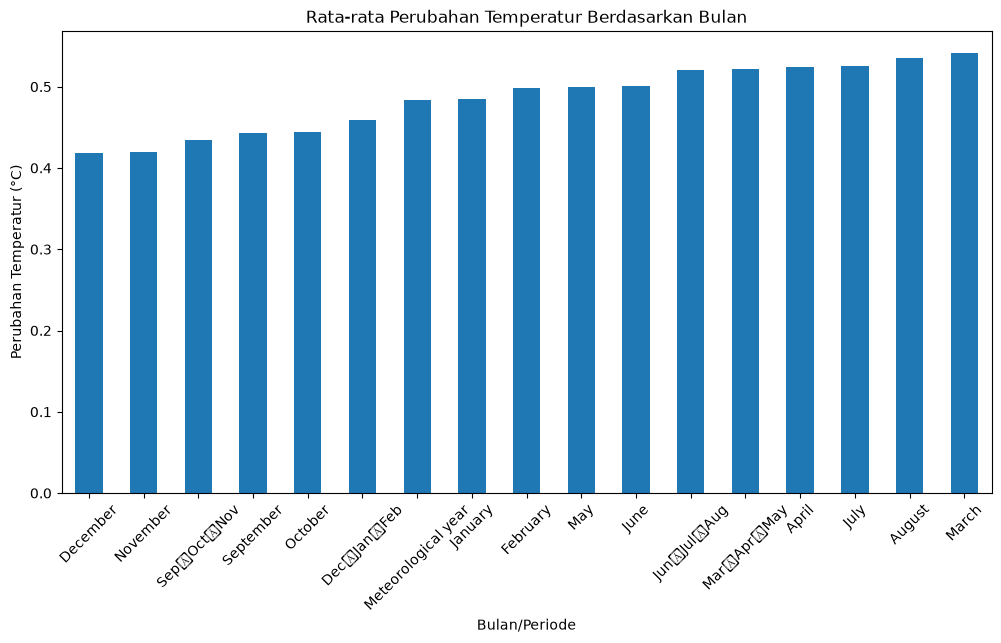

In [16]:
monthly_avg = (
    df_long.groupby("Months")["Temperature_Change"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(12, 6))

monthly_avg.plot(kind="bar")

plt.title("Rata-rata Perubahan Temperatur Berdasarkan Bulan")
plt.xlabel("Bulan/Periode")
plt.ylabel("Perubahan Temperatur (°C)")
plt.xticks(rotation=45)

plt.show()